<a href="https://colab.research.google.com/github/oumaymazerrik/-End-to-End-Predictive-Maintenance-Pipeline/blob/main/Assignment1_PredictiveMaintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5 Practical assignment - End-to-End Predictive Maintenance Pipeline

**Duration:** 4 hours (in class) · **Teams:** 2–3 students · **Deliverable:** this notebook, completed, run top-to-bottom, with the short report in Part 7

In this lab, you will build a predictive-maintenance pipeline for turbofan engines, from raw sensor data to a trained machine-learning model that predicts the Remaining Useful Life (RUL) of each engine. You will also have the opportunity to extend this pipeline with a streaming job that generates alerts when new sensor readings arrive (optional Part 5).

You will reuse concepts and techniques from previous labs: Spark DataFrames and SparkSQL, the RDD API, query plans and optimization (Lab 2), and Structured Streaming (Lab 3). You will also apply Spark MLlib to train and evaluate regression models.

The selected model will serve as a classical machine-learning baseline for the distributed deep-learning model you will develop in Lab 6. In Part 6, you will prepare and export the sensor data and baseline results needed for that next lab.

Through this assignment, you will:
- Build a data processing pipeline: ingest raw sensor data, convert it into typed Parquet datasets, validate and clean the data, and organize the processing stages using the Bronze, Silver, and Gold data-layer approach.
- Apply distributed data processing: use Spark DataFrames, Spark SQL, and window functions to explore sensor measurements, construct RUL labels, and engineer temporal features.
- Develop a machine-learning workflow: use Spark MLlib to build regression pipelines, train and compare models, and evaluate their predictive performance.
- Understand production-oriented processing: explore how the pipeline can be extended to process incoming sensor data and generate predictive-maintenance alerts through Structured Streaming (optional Part 5).
- Prepare for distributed deep learning: export the processed data and baseline evaluation results for use in Lab 6, where you will develop a distributed deep-learning model.

**Team members**

| Member 1 | Member 2 | Member 3 (optional) |
|---|---|---|
|  | | |

## Conventions used in this notebook

- `TODO x.y` : code you must write. Replace every `...`. Do not change function names or signatures: later parts call them.
- ✅ **Check cells** : run them after each TODO. If a check fails, fix your code before moving on.
- 🛟 **Fallback cells** : see below. Only use them if you are stuck.
- ⭐ **Optional** : bonus work for fast teams. Skip it if you are behind schedule.
- ❓ **Questions** : answer them briefly in the report (Part 7), not in the middle of the code.

### 🛟 Fallback checkpoints

Each part starts from the output of the previous one. If your team is stuck and running out of time, do not lose the rest of the lab: ask the instructor for the fallback pack, unzip it as `fallback/` next to this notebook, and restart from the next checkpoint.

| Checkpoint | Folder | Contains | Use it to start… |
|---|---|---|---|
| **CP0** | `data/CMAPSSData/` | raw NASA files (`train/test/RUL_FD001.txt`) | Part 1, if the download fails |
| **CP1** | `fallback/cp1_bronze/` | Bronze tables `train`, `test`, `rul_truth` | Part 2 |
| **CP2** | `fallback/cp2_silver/` | Silver tables + selected sensors | Part 3 |
| **CP3** | `fallback/cp3_gold/` | Gold feature tables + feature list | Part 4 (or 6) |
| **CP4** | `fallback/cp4_model/` | trained baseline `PipelineModel` | Part 5 |

How to use it: at the top of the part you want to start from, set `USE_FALLBACK = True` in the 🛟 cell and run it. It reloads **all** checkpoints up to that point (and reference versions of the functions later parts need), so the following cells work.
Using a fallback costs the points of the part you skipped only — you can still earn everything after it. Say in your report which fallbacks you used.

**Grading (100 pts)**

| Part 1 | Part 2 | Part 3 | Part 4 | Part 5 | Part 6 | Report | Reproducibility* |
|---|---|---|---|---|---|---|---|
| 10 | 15 | 20 | 25 | 10 | 5 | 10 | 5 |


### Context — the C-MAPSS dataset

NASA's **C-MAPSS** (Commercial Modular Aero-Propulsion System Simulation) dataset simulates fleets of turbofan engines. Every engine starts healthy with some unknown initial wear, then a fault appears and grows until the engine fails.

- **`train_FD001.txt`** — 100 engines recorded until failure (run-to-failure).
- **`test_FD001.txt`** — 100 other engines, recordings stopped some time before failure.
- **`RUL_FD001.txt`** — the true remaining life of each test engine at its last recorded cycle (line *i* ↔ engine *i*).

Each line = one engine × one cycle (≈ one flight): `unit_id, cycle, 3 operational settings, 21 sensors`, separated by spaces.
FD001 is the simplest subset (one operating condition, one fault mode). FD002–FD004 add operating conditions and fault modes (⭐ bonus).

**Target.** For a training engine, at cycle *t*: `RUL = last_cycle − t`. Early in life the engine shows no degradation, so the true RUL is not predictable from sensors; the standard practice is to cap the label: `rul_capped = min(RUL, 125)` (*piece-wise linear* target).

```
 raw .txt ─► P1 BRONZE ─► P2 SILVER ─────► P3 GOLD ─────► P4 MLlib model ─► P5 streaming scoring + alerts
             typed         cleaned +         rolling          baseline           (foreachBatch)
             parquet       RUL labels        window feats
                              │                                   │
                              └────────► P6 dl_ready/ + baseline_metrics.json ───────► Lab 6 (distributed DL)
```

---
## Part 0 — Setup

Requirements (same environment as the previous labs): Java 17+, `pyspark >= 3.4` (tested with 4.2), `pandas`, `pyarrow`, `matplotlib`. Keep the Spark UI (http://localhost:4040) open in a browser tab ; you will need it.

# Installer *Pyspark*

In [1]:
!pip -q install pyspark==3.5.0 pyarrow pandas numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.0 which is incompatible.


In [2]:
import pyspark
print("PySpark version:", pyspark.__version__)

PySpark version: 3.5.0


In [3]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("PredictiveMaintenance") \
    .master("local[*]") \
    .getOrCreate()

print("Spark version:", spark.version)

Spark version: 3.5.0


In [16]:
from google.colab import output

output.serve_kernel_port_as_window(
    4040,
    path="/jobs/index.html"
)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [17]:
import os, json, time, shutil, importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, DataFrame, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

spark = (SparkSession.builder
         .appName("Lab5-PredictiveMaintenance")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")      # small data: 200 partitions would be wasteful (Lab 2)
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.driver.memory", "4g")
         .config("spark.ui.showConsoleProgress", "false")  # no progress bars in the notebook (Spark UI: http://localhost:4040)
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Spark 3.5.0 | cores: 2


In [18]:
# ── Configuration ───────────────────────────────────────────────────────────
TEAM = {"name": "team-XX", "members": ["hala belmoukhtar", "oumayma zerrik" , "hamza el attar"]}   # ← edit

SUBSET = "FD001"           # keep FD001 for the graded part
RUL_CAP = 125              # piece-wise linear target
WINDOW_SIZE = 10           # cycles used for rolling features
ALERT_THRESHOLD = 30       # alert when predicted RUL < 30 cycles
SEED = 42

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "CMAPSSData"
OUT_DIR = BASE_DIR / "lab5_outputs"
FALLBACK_DIR = BASE_DIR / "fallback"
P = {name: OUT_DIR / name for name in ["bronze", "silver", "gold", "models", "stream", "dl_ready"]}
OUT_DIR.mkdir(exist_ok=True)

SETTING_COLS = [f"setting_{i}" for i in range(1, 4)]
SENSOR_COLS = [f"s{i}" for i in range(1, 22)]
RAW_COLS = ["unit_id", "cycle"] + SETTING_COLS + SENSOR_COLS
print(len(RAW_COLS), "raw columns")

26 raw columns


In [19]:
# ── Helpers (provided) ─────────────────────────────────────────────────────
def check(condition, message):
    """Self-check used throughout the lab."""
    if not condition:
        raise AssertionError("ERROR: " + message)
    print("OK: ", message)


def plan_stats(df: DataFrame) -> dict:
    """Count the main physical operators of a DataFrame's plan (no job is run)."""
    plan = df._jdf.queryExecution().executedPlan().toString()
    keys = {"shuffles (Exchange hashpartitioning)": "Exchange hashpartitioning",
            "BroadcastExchange": "BroadcastExchange",
            "SortMergeJoin": "SortMergeJoin",
            "BroadcastHashJoin": "BroadcastHashJoin",
            "Window": "Window ["}
    return {k: plan.count(v) for k, v in keys.items()}


def restore(cp: str) -> dict:
    """🛟 Load fallback checkpoints cp1..cp<n> and the reference functions later parts need.
    Usage:  globals().update(restore("cp2"))"""
    order = ["cp1", "cp2", "cp3", "cp4"]
    if not FALLBACK_DIR.exists():
        raise FileNotFoundError(f"No fallback pack at {FALLBACK_DIR} — ask the instructor for it.")
    ns, upto = {}, order.index(cp)
    read = lambda *parts: spark.read.parquet(str(FALLBACK_DIR.joinpath(*parts)))
    meta = lambda folder: json.loads((FALLBACK_DIR / folder / "meta.json").read_text())
    ns.update(bronze_train=read("cp1_bronze", "train"), bronze_test=read("cp1_bronze", "test"),
              rul_truth=read("cp1_bronze", "rul_truth"))
    if upto >= 1:
        ns.update(silver_train=read("cp2_silver", "train").cache(), silver_test=read("cp2_silver", "test").cache(),
                  FEATURE_SENSORS=meta("cp2_silver")["feature_sensors"])
    if upto >= 2:
        ns.update(gold_train=read("cp3_gold", "train"), gold_test=read("cp3_gold", "test"),
                  gold_test_last=read("cp3_gold", "test_last"), FEATURE_COLS=meta("cp3_gold")["feature_cols"])
    if upto >= 3:
        from pyspark.ml import PipelineModel
        ns.update(best_model=PipelineModel.load(str(FALLBACK_DIR / "cp4_model" / "best_pipeline")),
                  best_name=meta("cp4_model")["best_name"])
    # reference implementations of the functions used downstream
    spec = importlib.util.spec_from_file_location("reference_functions", FALLBACK_DIR / "reference_functions.py")
    ref = importlib.util.module_from_spec(spec); spec.loader.exec_module(ref)
    if upto >= 1:
        ns.update(label_train=ref.label_train, label_test=ref.label_test)
    if upto >= 2:
        ns.update(build_features=ref.build_features)
    print("🛟 restored up to", cp, "→", ", ".join(sorted(ns)))
    return ns

In [20]:
# ── Data (CP0) ──────────────────────────────────────────────────────────────
# Official source: NASA Prognostics Center of Excellence data repository
# ("Turbofan Engine Degradation Simulation"). The cell below fetches the FD001 files
# from a public GitHub mirror. If it fails (no internet / proxy), copy the files
# given by the instructor into data/CMAPSSData/  (= checkpoint CP0).
MIRROR = "https://raw.githubusercontent.com/hankroark/Turbofan-Engine-Degradation/master/CMAPSSData"
FILES = {"train": f"train_{SUBSET}.txt", "test": f"test_{SUBSET}.txt", "rul": f"RUL_{SUBSET}.txt"}

DATA_DIR.mkdir(parents=True, exist_ok=True)
for name in FILES.values():
    target = DATA_DIR / name
    if not target.exists():
        import urllib.request
        print("downloading", name, "...")
        urllib.request.urlretrieve(f"{MIRROR}/{name}", target)

for name in FILES.values():
    check((DATA_DIR / name).exists(), f"{name} present ({(DATA_DIR / name).stat().st_size/1e6:.1f} MB)")
print(open(DATA_DIR / FILES["train"]).readline())

downloading train_FD001.txt ...
downloading test_FD001.txt ...
downloading RUL_FD001.txt ...
OK:  train_FD001.txt present (3.5 MB)
OK:  test_FD001.txt present (2.2 MB)
OK:  RUL_FD001.txt present (0.0 MB)
1 1 -0.0007 -0.0004 100.0 518.67 641.82 1589.70 1400.60 14.62 21.61 554.36 2388.06 9046.19 1.30 47.47 521.66 2388.02 8138.62 8.4195 0.03 392 2388 100.00 39.06 23.4190  



---
## Part 1 — Ingestion → Bronze

The raw files are space-separated text with a trailing space at the end of every line (look at the line printed above). Reading them with `spark.read.csv(sep=" ")` gives two extra empty columns and guessed types — we want an explicit, typed result.

**Goals**
1. Parse the text files into a typed DataFrame with the 26 `RAW_COLS` + metadata columns.
2. Load the RUL ground truth, where the line number is the engine id.
3. Persist everything as the Bronze layer in Parquet.

**TODO 1.1** — Complete `parse_cmapss`.
- `spark.read.text()` gives one string column `value` per line.
- Split it on one or more whitespace characters (regex `\s+`) after trimming it.
- Cast `unit_id` and `cycle` to `int`, the 24 other columns to `double`, and name them with `RAW_COLS`.

In [21]:
def parse_cmapss(path: Path, split: str) -> DataFrame:
    """Parse a raw C-MAPSS text file into a typed DataFrame (RAW_COLS + metadata)."""
    raw = spark.read.text(str(path))

    # TODO 1.1a — Split each line into 26 values
    parts = F.split(F.trim(F.col("value")), r"\s+")

    # TODO 1.1b — Create 26 typed and named columns
    typed_cols = [
        parts.getItem(i).cast("int" if col in ["unit_id", "cycle"] else "double").alias(col)
        for i, col in enumerate(RAW_COLS)
    ]

    return (raw.select(*typed_cols)
               .withColumn("dataset", F.lit(SUBSET))
               .withColumn("split", F.lit(split))
               .withColumn("source_file", F.lit(path.name))
               .withColumn("ingested_at", F.current_timestamp()))


bronze_train = parse_cmapss(DATA_DIR / FILES["train"], "train")
bronze_test = parse_cmapss(DATA_DIR / FILES["test"], "test")

bronze_train.printSchema()

root
 |-- unit_id: integer (nullable = true)
 |-- cycle: integer (nullable = true)
 |-- setting_1: double (nullable = true)
 |-- setting_2: double (nullable = true)
 |-- setting_3: double (nullable = true)
 |-- s1: double (nullable = true)
 |-- s2: double (nullable = true)
 |-- s3: double (nullable = true)
 |-- s4: double (nullable = true)
 |-- s5: double (nullable = true)
 |-- s6: double (nullable = true)
 |-- s7: double (nullable = true)
 |-- s8: double (nullable = true)
 |-- s9: double (nullable = true)
 |-- s10: double (nullable = true)
 |-- s11: double (nullable = true)
 |-- s12: double (nullable = true)
 |-- s13: double (nullable = true)
 |-- s14: double (nullable = true)
 |-- s15: double (nullable = true)
 |-- s16: double (nullable = true)
 |-- s17: double (nullable = true)
 |-- s18: double (nullable = true)
 |-- s19: double (nullable = true)
 |-- s20: double (nullable = true)
 |-- s21: double (nullable = true)
 |-- dataset: string (nullable = false)
 |-- split: string (nullable

**TODO 1.2** — Build `rul_truth(unit_id, true_rul)` from `RUL_FD001.txt`.
A DataFrame has no notion of *line number*, and the order of rows is not guaranteed. Use the **RDD API** instead: `sc.textFile(...)` then `zipWithIndex()` gives each line its position. Remember that engine ids start at **1**.

In [22]:
sc = spark.sparkContext

# TODO 1.2 — RDD of (unit_id, true_rul) tuples, then a DataFrame

rul_truth = (
    sc.textFile(str(DATA_DIR / FILES["rul"]))
    .map(lambda line: line.strip())
    .filter(lambda line: line != "")
    .zipWithIndex()
    .map(lambda x: (int(x[1]) + 1, int(x[0])))
    .toDF(["unit_id", "true_rul"])
)

rul_truth.show(3)

+-------+--------+
|unit_id|true_rul|
+-------+--------+
|      1|     112|
|      2|      98|
|      3|      69|
+-------+--------+
only showing top 3 rows



In [23]:
# ✅ Checks — Part 1 (FD001 values)
check(bronze_train.columns[:26] == RAW_COLS, "26 raw columns with the expected names and order")
check(dict(bronze_train.dtypes)["unit_id"] == "int" and dict(bronze_train.dtypes)["s2"] == "double", "types cast")
check(bronze_train.count() == 20631, "train: 20 631 rows")
check(bronze_test.count() == 13096, "test: 13 096 rows")
check(bronze_train.select("unit_id").distinct().count() == 100, "train: 100 engines")
check(bronze_train.filter(F.col("s21").isNull()).count() == 0, "no null in the last column (trailing space handled)")
check(rul_truth.count() == 100 and rul_truth.filter("unit_id = 1").first().true_rul == 112, "rul_truth: 100 rows, engine 1 → 112")

OK:  26 raw columns with the expected names and order
OK:  types cast
OK:  train: 20 631 rows
OK:  test: 13 096 rows
OK:  train: 100 engines
OK:  no null in the last column (trailing space handled)
OK:  rul_truth: 100 rows, engine 1 → 112


**TODO 1.3** — Write the **Bronze** layer: three Parquet tables under `P["bronze"]` (`train`, `test`, `rul_truth`), overwriting any previous run. Then re-read them so that the rest of the lab starts from Parquet, not from text.

In [24]:
# TODO 1.3 — write the three tables, then reload them

bronze_train.write.mode("overwrite").parquet(str(P["bronze"] / "train"))
bronze_test.write.mode("overwrite").parquet(str(P["bronze"] / "test"))
rul_truth.write.mode("overwrite").parquet(str(P["bronze"] / "rul_truth"))

bronze_train = spark.read.parquet(str(P["bronze"] / "train"))
bronze_test = spark.read.parquet(str(P["bronze"] / "test"))
rul_truth = spark.read.parquet(str(P["bronze"] / "rul_truth"))

check(bronze_train.count() == 20631, "Bronze written and re-read")

OK:  Bronze written and re-read



### ❓ Q1. Give two reasons to store Bronze as Parquet rather than keeping the text files. Why did we use the RDD API for the RUL file?

### ✅ R1.

**Two reasons for using Parquet:**

1. **Better performance:** Parquet is a columnar format that allows Spark to read only the required columns, making data processing faster.
2. **Less storage space:** Parquet supports compression and preserves data types, unlike raw text files.

**Why did we use the RDD API for the RUL file?**

We used the RDD API because the RUL file contains only RUL values without engine IDs. The `zipWithIndex()` method allows us to assign an index to each line and generate the corresponding `unit_id`, starting from 1. We then convert the RDD into a DataFrame.


---
## Part 2 — Exploration & labelling → Silver

In [25]:
# 🛟 FALLBACK — set to True ONLY if Part 1 is not finished (loads CP1)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp1"))

**TODO 2.1** — With SparkSQL on a temporary view, compute the number of engines and the **min / average / max lifetime** (lifetime = last cycle of an engine) of the training fleet. One query, with a sub-query.

In [26]:
bronze_train.createOrReplaceTempView("bronze_train")

# TODO 2.1
lifetimes = spark.sql("""
    SELECT
        COUNT(*) AS n_engines,
        MIN(lifetime) AS min_life,
        AVG(lifetime) AS avg_life,
        MAX(lifetime) AS max_life
    FROM (
        SELECT unit_id, MAX(cycle) AS lifetime
        FROM bronze_train
        GROUP BY unit_id
    )
""")

lifetimes.show()

+---------+--------+--------+--------+
|n_engines|min_life|avg_life|max_life|
+---------+--------+--------+--------+
|      100|     128|  206.31|     362|
+---------+--------+--------+--------+



In [27]:
# ✅ Check
row = lifetimes.first()
check((row.n_engines, row.min_life, row.max_life) == (100, 128, 362), "100 engines, lifetimes between 128 and 362 cycles")

OK:  100 engines, lifetimes between 128 and 362 cycles


**TODO 2.2** — Several sensors and settings are (almost) **constant** in FD001: they carry no information and only add noise and cost.
Compute the standard deviation of **all** settings and sensors on the training set **in a single aggregation** (one pass over the data — not one job per column), then:
- `DROP_COLS` = columns whose std is `< STD_THRESHOLD`,
- `FEATURE_SENSORS` = the sensors we keep (in their original order).

In [28]:
STD_THRESHOLD = 0.01

# TODO 2.2

# Calculate standard deviation for all settings and sensors
cols = SETTING_COLS + SENSOR_COLS

stds = bronze_train.agg(
    *[F.stddev(c).alias(c) for c in cols]
).first().asDict()

# Columns with very low standard deviation
DROP_COLS = [
    c for c in cols if stds[c] < STD_THRESHOLD
]

# Keep useful sensors in their original order
FEATURE_SENSORS = [
    c for c in SENSOR_COLS if c not in DROP_COLS
]

print("dropped :", DROP_COLS)
print("kept    :", FEATURE_SENSORS)

dropped : ['setting_1', 'setting_2', 'setting_3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
kept    : ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [29]:
# ✅ Check
check(len(FEATURE_SENSORS) == 14, f"14 informative sensors kept ({len(FEATURE_SENSORS)})")
check(all(c in DROP_COLS for c in ["s1", "s5", "s10", "s16", "s18", "s19", "setting_3"]), "constant columns dropped")

OK:  14 informative sensors kept (14)
OK:  constant columns dropped


**TODO 2.3** — Create the labels with window functions (no join back to an aggregate, no Python UDF).

- `label_train(df)`: `rul = max cycle of the engine − cycle`, `rul_capped = min(rul, RUL_CAP)`.
- `label_test(df, rul_truth, use_broadcast)`: a test engine stops `true_rul` cycles before failure, so at cycle *t*: `rul = true_rul + (last recorded cycle − t)`. Join with `rul_truth`; when `use_broadcast=True`, use a **broadcast hint** (you will compare both versions in Part 3).

Both functions return the input columns + `rul` (int) and `rul_capped` (int); drop helper columns such as `true_rul`.

In [30]:
def label_train(df: DataFrame) -> DataFrame:
    # TODO 2.3a
    w = Window.partitionBy("unit_id")

    return (df
            .withColumn("rul",
                        (F.max("cycle").over(w) - F.col("cycle")).cast("int"))
            .withColumn("rul_capped",
                        F.least(F.col("rul"), F.lit(RUL_CAP)).cast("int")))


def label_test(df: DataFrame, rul_truth: DataFrame, use_broadcast: bool = True) -> DataFrame:
    # TODO 2.3b
    w = Window.partitionBy("unit_id")

    truth = F.broadcast(rul_truth) if use_broadcast else rul_truth

    return (df
            .withColumn("max_cycle", F.max("cycle").over(w))
            .join(truth, on="unit_id", how="inner")
            .withColumn("rul",
                        (F.col("true_rul") + F.col("max_cycle") - F.col("cycle")).cast("int"))
            .withColumn("rul_capped",
                        F.least(F.col("rul"), F.lit(RUL_CAP)).cast("int"))
            .drop("max_cycle", "true_rul"))

**TODO 2.4** — Build the Silver tables: labelled data restricted to `SILVER_COLS`, write them to `P["silver"]` (`train`, `test`), reload them and cache them (they are reused by Parts 3, 4 and 6).

In [31]:
SILVER_COLS = ["unit_id", "cycle"] + FEATURE_SENSORS + ["rul", "rul_capped", "split"]

# TODO 2.4

# Create Silver DataFrames
silver_train = label_train(bronze_train).select(*SILVER_COLS)
silver_test = label_test(bronze_test, rul_truth).select(*SILVER_COLS)

# Save as Parquet
silver_train.write.mode("overwrite").parquet(str(P["silver"] / "train"))
silver_test.write.mode("overwrite").parquet(str(P["silver"] / "test"))

In [32]:
# ✅ Checks — Part 2
last_rows = silver_train.groupBy("unit_id").agg(F.max("cycle").alias("c")).join(silver_train, "unit_id").filter("cycle = c")
check(last_rows.filter("rul != 0").count() == 0, "every training engine has RUL = 0 at its last cycle")
check(silver_train.agg(F.max("rul_capped")).first()[0] == RUL_CAP, "rul_capped is capped at RUL_CAP")
t1 = silver_test.filter("unit_id = 1").orderBy(F.desc("cycle")).first()
check(t1.rul == 112 and t1.cycle == 31, "test engine 1: last cycle 31, RUL 112")
check(silver_test.filter("unit_id = 1 AND cycle = 1").first().rul == 142, "test engine 1: RUL 142 at cycle 1")


OK:  every training engine has RUL = 0 at its last cycle
OK:  rul_capped is capped at RUL_CAP
OK:  test engine 1: last cycle 31, RUL 112
OK:  test engine 1: RUL 142 at cycle 1


Provided — look at how sensors evolve as engines approach failure (x-axis = RUL, failure on the right).

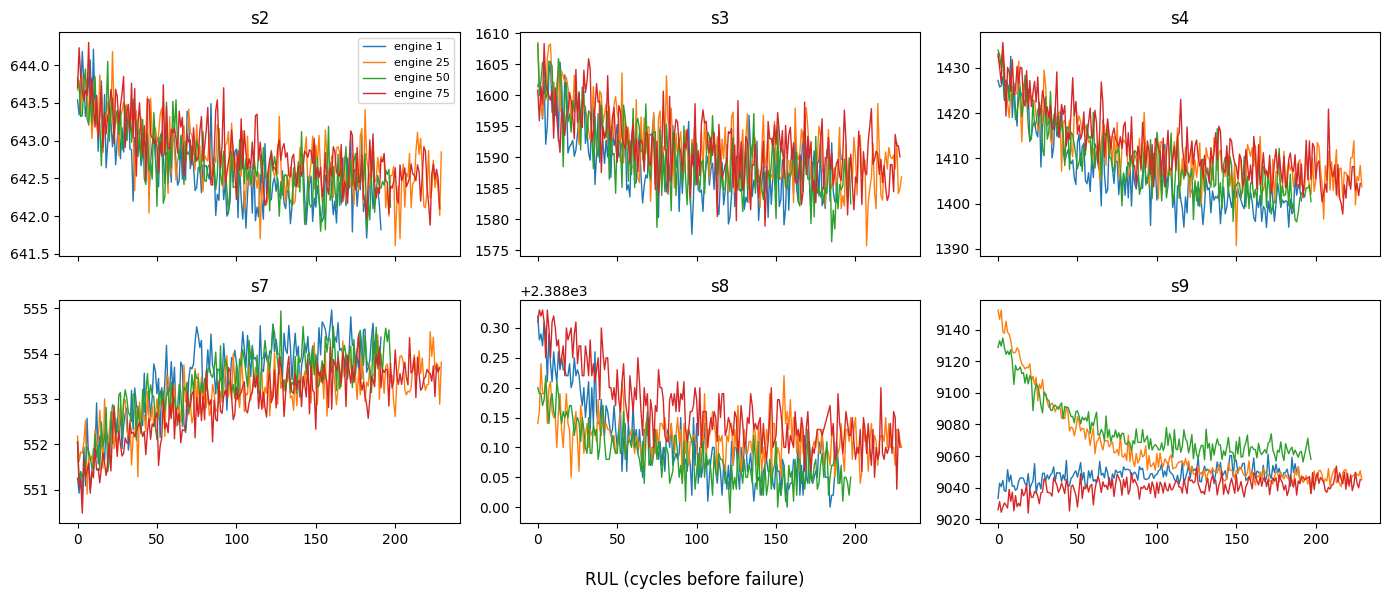

In [33]:
sample_units = [1, 25, 50, 75]
pdf = silver_train.filter(F.col("unit_id").isin(sample_units)).toPandas()   # small: OK to collect
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, s in zip(axes.flat, FEATURE_SENSORS[:6]):
    for u, g in pdf.groupby("unit_id"):
        ax.plot(g["rul"], g[s], lw=1, label=f"engine {u}")
    ax.set_title(s); ax.invert_xaxis()
axes[0, 0].legend(fontsize=8); fig.supxlabel("RUL (cycles before failure)"); plt.tight_layout(); plt.show()

❓ **Q2.** Why is capping the label at 125 reasonable (look at the plot)? Which sensors were dropped and why is that safe for FD001 but maybe not for FD002/FD004?





### ❓ Q2. Why is capping the label at 125 reasonable? Which sensors were dropped and why is that safe for FD001 but maybe not for FD002/FD004?

### ✅ R2.

**1. Why cap RUL at 125?**

At the beginning of an engine's life, sensor values are relatively stable and show little degradation. Capping RUL at 125 prevents the model from trying to predict exact remaining lifetimes when the engine is still healthy.

**2. Which sensors were dropped?**

The near-constant sensors are `s1`, `s5`, `s6`, `s10`, `s16`, `s18`, and `s19`.

They were removed because their standard deviation is very low, meaning they provide little useful information.

**3. Why is this safe for FD001 but not necessarily FD002/FD004?**

FD001 has only one operating condition, so near-constant sensors provide little information.

However, FD002 and FD004 contain multiple operating conditions. Some sensors may vary across these conditions and become useful.

Therefore, feature selection should be recalculated for each dataset.


---
## Part 3 — Feature engineering → Gold

A single reading is noisy; degradation is a trend. For every kept sensor we add, over the last `WINDOW_SIZE` cycles of the same engine (current cycle included):
- the rolling **mean** → `<sensor>_mean_<W>`
- the rolling **standard deviation** → `<sensor>_std_<W>` (null on the first cycle → replace by 0)

Final feature set: `cycle` + the 14 raw sensors + 14 means + 14 stds = 43 features.

In [34]:
# 🛟 FALLBACK — set to True ONLY if Part 2 is not finished (loads CP1 + CP2)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp2"))

**TODO 3.1** — Implement `build_features`. Requirements (they matter for Part 5, which reuses this function on streaming micro-batches):
- one window spec, **rows**-based (not range-based), per engine, ordered by cycle;
- build all new columns in **one `select`** — not 28 chained `withColumn` calls (Lab 2: each one adds a projection to the plan);
- it must work on any DataFrame having `unit_id`, `cycle` and the sensor columns (with or without labels).

In [35]:
def build_features(df: DataFrame, sensors: list, window_size: int = WINDOW_SIZE) -> DataFrame:
    # TODO 3.1

    w = (Window.partitionBy("unit_id")
         .orderBy("cycle")
         .rowsBetween(-(window_size - 1), 0))

    features = []

    for s in sensors:
        features.append(F.avg(s).over(w).alias(f"{s}_mean_{window_size}"))
        features.append(F.coalesce(F.stddev(s).over(w), F.lit(0.0)).alias(f"{s}_std_{window_size}"))

    return df.select("*", *features)


FEATURE_COLS = (["cycle"] + FEATURE_SENSORS
                + [f"{s}_mean_{WINDOW_SIZE}" for s in FEATURE_SENSORS]
                + [f"{s}_std_{WINDOW_SIZE}" for s in FEATURE_SENSORS])

print(len(FEATURE_COLS), "features")

43 features


In [36]:
# ✅ Checks — TODO 3.1
gold_check = build_features(silver_train, FEATURE_SENSORS)
expected = silver_train.filter("unit_id = 1 AND cycle BETWEEN 11 AND 20").agg(F.avg("s2")).first()[0]
got = gold_check.filter("unit_id = 1 AND cycle = 20").first()[f"s2_mean_{WINDOW_SIZE}"]
check(len(FEATURE_COLS) == 43 and all(c in gold_check.columns for c in FEATURE_COLS), "43 feature columns present")
check(abs(expected - got) < 1e-9, "rolling mean at cycle 20 = mean of cycles 11..20")
check(gold_check.filter("cycle = 1").agg(F.max(f"s2_std_{WINDOW_SIZE}")).first()[0] == 0.0, "std = 0 on the first cycle")
nulls = gold_check.select([F.sum(F.col(c).isNull().cast("int")) for c in FEATURE_COLS]).first()
check(sum(nulls) == 0, "no nulls in the 43 features")

OK:  43 feature columns present
OK:  rolling mean at cycle 20 = mean of cycles 11..20
OK:  std = 0 on the first cycle
OK:  no nulls in the 43 features


**TODO 3.2 — Read the plan (Lab 2).** Compare the physical plans of the *test* pipeline `bronze → label_test → build_features` without and with the broadcast hint.
Spark broadcasts small tables automatically (`spark.sql.autoBroadcastJoinThreshold`, 10 MB by default), so we disable that first to see the naive plan.
Use `plan_stats()` (provided) and, if you want the details, `.explain(mode="formatted")`.

In [37]:
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

# TODO 3.2 — build both DataFrames (do not execute them)

naive = label_test(bronze_test, rul_truth, use_broadcast=False)

optimized = label_test(bronze_test, rul_truth, use_broadcast=True)

# Compare execution plans
print(pd.DataFrame({
    "naive": plan_stats(naive),
    "broadcast": plan_stats(optimized)
}))

spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")

                                      naive  broadcast
shuffles (Exchange hashpartitioning)      3          1
BroadcastExchange                         0          1
SortMergeJoin                             1          0
BroadcastHashJoin                         0          1
Window                                    1          1



### ❓ Q3. Shuffle Analysis and Broadcast Optimization

### ✅ R3.

**1. Number of shuffles**

- **Naive plan:** 3 shuffles.
- **Broadcast plan:** 1 shuffle.

**2. Why does the naive plan have extra shuffles?**

The naive plan uses a `SortMergeJoin`, which requires both datasets to be partitioned by the join key (`unit_id`).

However, `unit_id` has different types:
- `bronze_test`: Integer
- `rul_truth`: Long

Spark casts the join key to a common type and repartitions the data for the join, causing additional shuffles.

**3. Why does Broadcast need only one shuffle?**

Broadcast Join sends the small `rul_truth` table to all executors, avoiding the shuffles required by the SortMergeJoin.

Both window calculations are partitioned by `unit_id`, so Spark can reuse the same partitioning without an additional shuffle.

**4. What if the test dataset were 1 TB?**

The naive plan would require expensive data redistribution across the cluster, increasing network traffic, disk I/O, and execution time.

Broadcast Join would be more efficient because only the small RUL table needs to be broadcast.


⭐ **Optional 3.2b** — fix the root cause of the extra shuffle in `rul_truth` and show the new `plan_stats` of the naive version.

In [38]:
# ⭐ Optional 3.2b
# Optional 3.2b — Fix the join key type

from pyspark.sql import functions as F

# Convert unit_id to Integer
rul_truth_fixed = rul_truth.withColumn(
    "unit_id", F.col("unit_id").cast("int")
)

# Disable automatic broadcast
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

# Build naive plan with corrected types
naive_fixed = label_test(
    bronze_test,
    rul_truth_fixed,
    use_broadcast=False
)

# Compare execution plans
print(pd.DataFrame({
    "naive_before": plan_stats(naive),
    "naive_fixed": plan_stats(naive_fixed)
}))

# Restore default configuration
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")

                                      naive_before  naive_fixed
shuffles (Exchange hashpartitioning)             3            2
BroadcastExchange                                0            0
SortMergeJoin                                    1            1
BroadcastHashJoin                                0            0
Window                                           1            1



### 📝 Observation — Optional 3.2b

After converting `unit_id` from `Long` to `Integer`, the number of shuffles decreased from **3 to 2**.

This confirms that the data type mismatch was causing an extra shuffle during the join.

The `SortMergeJoin` and `Window` operations remain unchanged.

**Conclusion:** Using consistent data types for join keys helps Spark reduce unnecessary data redistribution and improve execution efficiency.


**TODO 3.3** — Build and write the Gold layer under `P["gold"]`:
- `train` = features of `silver_train`; `test` = features of `silver_test`;
- `test_last` = the last recorded cycle of each test engine (this is the official C-MAPSS evaluation point: one prediction per engine). Use a window function, not a join.
Keep `unit_id`, `FEATURE_COLS`, `rul`, `rul_capped`. Reload them afterwards.

In [39]:
GOLD_COLS = ["unit_id"] + FEATURE_COLS + ["rul", "rul_capped"]

# TODO 3.3

# 1. Build Gold DataFrames
gold_train = build_features(silver_train, FEATURE_SENSORS).select(*GOLD_COLS)
gold_test = build_features(silver_test, FEATURE_SENSORS).select(*GOLD_COLS)

# 2. Select the last cycle of each test engine
w = Window.partitionBy("unit_id").orderBy(F.col("cycle").desc())

gold_test_last = (
    gold_test
    .withColumn("rn", F.row_number().over(w))
    .filter(F.col("rn") == 1)
    .drop("rn")
)

# 3. Save Gold tables as Parquet
gold_train.write.mode("overwrite").parquet(str(P["gold"] / "train"))
gold_test.write.mode("overwrite").parquet(str(P["gold"] / "test"))
gold_test_last.write.mode("overwrite").parquet(str(P["gold"] / "test_last"))

# 4. Reload Gold tables
gold_train = spark.read.parquet(str(P["gold"] / "train"))
gold_test = spark.read.parquet(str(P["gold"] / "test"))
gold_test_last = spark.read.parquet(str(P["gold"] / "test_last"))

In [40]:
# ✅ Checks — Part 3
check(gold_train.count() == 20631 and gold_test.count() == 13096, "Gold row counts preserved")
check(gold_test_last.count() == 100, "test_last: one row per test engine")
check(gold_test_last.filter("unit_id = 1").first().rul == 112, "test_last engine 1 has RUL 112")

OK:  Gold row counts preserved
OK:  test_last: one row per test engine
OK:  test_last engine 1 has RUL 112


## Part 4 — Modelling with Spark MLlib

We train three regressors on `rul_capped` and compare them on a validation set of engines, then evaluate the best one on the official test points (`gold_test_last`).

⚠️ **Data leakage.** Consecutive cycles of the same engine are almost identical. If you split *rows* at random, the model sees cycle 101 in training and is evaluated on cycle 102 of the same engine → results look excellent and mean nothing. The split must be done by engine.

In [41]:
# 🛟 FALLBACK — set to True ONLY if Part 3 is not finished (loads CP1 → CP3)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp3"))

In [42]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor

**TODO 4.1** — Split the engines 80 / 20 into `train_df` and `val_df` (20 validation engines). Use `SEED` so the split is reproducible. Cache both DataFrames.

In [43]:
import random

# TODO 4.1

# Get all training engine IDs
unit_ids = sorted([
    row.unit_id
    for row in gold_train.select("unit_id").distinct().collect()
])

# Randomly select 20 engines for validation
val_units = random.Random(SEED).sample(unit_ids, 20)

# Split data by engine
train_df = gold_train.filter(~F.col("unit_id").isin(val_units))
val_df = gold_train.filter(F.col("unit_id").isin(val_units))

print(train_df.count(), val_df.count())

16738 3893


In [44]:
# ✅ Check
tu = {r.unit_id for r in train_df.select("unit_id").distinct().collect()}
vu = {r.unit_id for r in val_df.select("unit_id").distinct().collect()}
check(len(vu) == 20 and len(tu) == 80 and not (tu & vu), "80 train engines / 20 validation engines, no overlap")

OK:  80 train engines / 20 validation engines, no overlap


**TODO 4.2** — Two building blocks:
- `make_pipeline(regressor)`: `VectorAssembler(FEATURE_COLS → "features_raw")` → `StandardScaler(→ "features", withMean & withStd)` → `regressor`.
- `evaluate(pred_df, label_col)`: returns a dict with `rmse`, `mae`, the NASA score and `n`, computed in one Spark aggregation.

The NASA score penalises *late* predictions (predicted RUL > true RUL: the engine fails before maintenance) more than early ones. With `d = prediction − label`:
$s = \sum_i \left(e^{-d_i/13} - 1\right)$ if $d_i < 0$, and $\left(e^{d_i/10} - 1\right)$ otherwise. Lower is better.

In [45]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.sql import functions as F

LABEL = "rul_capped"


def make_pipeline(regressor) -> Pipeline:
    # TODO 4.2a

    assembler = VectorAssembler(
        inputCols=FEATURE_COLS,
        outputCol="features_raw"
    )

    scaler = StandardScaler(
        inputCol="features_raw",
        outputCol="features",
        withMean=True,
        withStd=True
    )

    return Pipeline(stages=[assembler, scaler, regressor])


def evaluate(pred_df: DataFrame, label_col: str = LABEL, pred_col: str = "prediction") -> dict:
    # TODO 4.2b

    d = F.col(pred_col) - F.col(label_col)

    nasa = F.when(
        d < 0,
        F.exp(-d / 13) - 1
    ).otherwise(
        F.exp(d / 10) - 1
    )

    result = pred_df.agg(
        F.sqrt(F.avg(d * d)).alias("rmse"),
        F.avg(F.abs(d)).alias("mae"),
        F.sum(nasa).alias("nasa_score"),
        F.count("*").alias("n")
    )

    return result.first().asDict()

In [46]:
# ✅ Check (on a toy DataFrame)
toy = spark.createDataFrame([(10.0, 0.0), (0.0, 13.0)], ["prediction", LABEL])
m = evaluate(toy)
check(abs(m["rmse"] - np.sqrt((100 + 169) / 2)) < 1e-3 and abs(m["mae"] - 11.5) < 1e-3, "rmse / mae")
check(abs(m["nasa_score"] - ((np.exp(1) - 1) + (np.exp(1) - 1))) < 1e-3, "NASA score")

OK:  rmse / mae
OK:  NASA score


**TODO 4.3** — Train the three candidates on `train_df`, evaluate each on `val_df`, record the training time, and collect the results in a pandas DataFrame `results` (one row per model).

In [47]:
candidates = {
    "LinearRegression": LinearRegression(featuresCol="features", labelCol=LABEL),
    "RandomForest": RandomForestRegressor(featuresCol="features", labelCol=LABEL,
                                          numTrees=100, maxDepth=10, seed=SEED),
    "GBT": GBTRegressor(featuresCol="features", labelCol=LABEL,
                        maxIter=80, maxDepth=5, stepSize=0.1, seed=SEED),
}

models, rows = {}, []

for name, reg in candidates.items():
    # TODO 4.3 — fit, time, predict, evaluate

    start = time.time()

    pipeline = make_pipeline(reg)
    model = pipeline.fit(train_df)

    training_time = time.time() - start

    predictions = model.transform(val_df)
    metrics = evaluate(predictions)

    models[name] = model

    rows.append({
        "model": name,
        **metrics,
        "train_time_s": training_time
    })

results = pd.DataFrame(rows).set_index("model").sort_values("rmse")
results

,rmse,mae,nasa_score,n,train_time_s
model,,,,,
RandomForest,15.918636,10.327298,33006.481722,3893,56.590705
GBT,16.964912,11.262555,41230.908873,3893,62.415750
LinearRegression,19.613221,16.214157,36570.561043,3893,8.867300


In [48]:
# ✅ Check
check(len(results) == 3 and results["rmse"].min() < 25, f"3 models evaluated, best validation RMSE = {results['rmse'].min():.1f} (< 25)")

OK:  3 models evaluated, best validation RMSE = 15.9 (< 25)


⭐ **Optional 4.3b** — Tune the best tree model with a small grid (e.g. `maxDepth ∈ {4, 6}`, `maxIter ∈ {60, 120}`) using the same engine split.
Why can't we simply use `TrainValidationSplit` or `CrossValidator` here?

In [49]:
# ⭐ Optional — your tuning loop here
best_tree = results.loc[["RandomForest", "GBT"], "rmse"].idxmin()

rows_tuning = []

for depth in [4, 6]:
    for n in [60, 120]:

        if best_tree == "GBT":
            reg = GBTRegressor(
                featuresCol="features",
                labelCol=LABEL,
                maxDepth=depth,
                maxIter=n,
                seed=SEED
            )
        else:
            reg = RandomForestRegressor(
                featuresCol="features",
                labelCol=LABEL,
                maxDepth=depth,
                numTrees=n,
                seed=SEED
            )

        model = make_pipeline(reg).fit(train_df)
        pred = model.transform(val_df)
        metrics = evaluate(pred)

        rows_tuning.append({
            "maxDepth": depth,
            "trees": n,
            **metrics
        })

tuning_results = pd.DataFrame(rows_tuning).sort_values("rmse")
print("Tuned model:", best_tree)
display(tuning_results)

Tuned model: RandomForest


,maxDepth,trees,rmse,mae,nasa_score,n
2,6,60,16.427114,11.013531,37881.276137,3893
3,6,120,16.446140,11.025440,37604.475996,3893
1,4,120,17.298013,12.384940,42927.908432,3893
0,4,60,17.377871,12.408734,43755.225181,3893



### 📝 Observation — Hyperparameter Tuning

We tuned the Random Forest model using different values of `maxDepth` and `numTrees`.

The best tested configuration was **maxDepth = 6** and **numTrees = 60**, achieving an RMSE of **16.43**.

Increasing the number of trees from 60 to 120 did not improve RMSE significantly.

However, the original model achieved a better validation RMSE of **15.9**.

**Conclusion:** The tested hyperparameter configurations did not improve the original model, so we keep the original model for final evaluation.


**TODO 4.4** — Final evaluation.
1. `best_name` = the model with the lowest validation RMSE.
2. Re-fit that pipeline on the whole `gold_train` (all 100 engines) → `best_model`.
3. Predict on `gold_test_last` → `test_pred`, evaluate against the true `rul` (not capped) → `test_metrics`.

In [50]:
# TODO 4.4

# Select the best model based on validation RMSE
best_name = results.index[0]

# Get the trained model
best_model = models[best_name]

# Predict on the official test set
test_pred = best_model.transform(gold_test_last)

# Evaluate predictions using the real RUL
test_metrics = evaluate(test_pred, label_col="rul")

print(best_name, test_metrics)

RandomForest {'rmse': 18.323670971930678, 'mae': 13.480831469531797, 'nasa_score': 716.6258263740938, 'n': 100}


OK:  test RMSE on 100 engines = 18.3


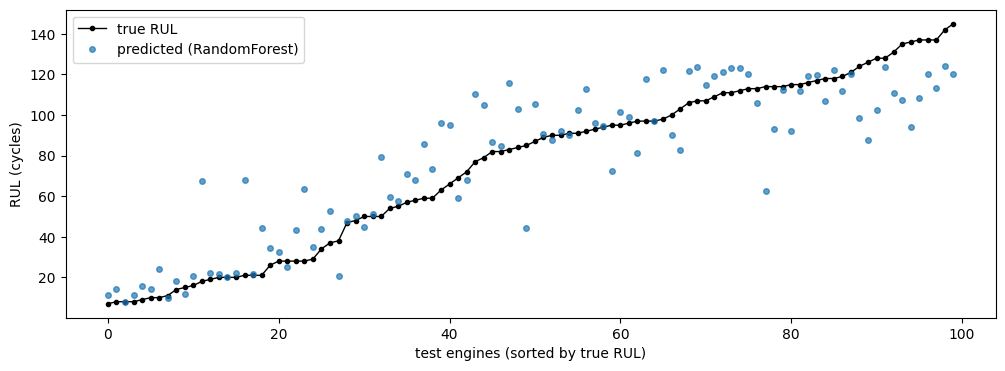

In [51]:
# ✅ Check + plot (provided)
check(test_metrics["n"] == 100 and test_metrics["rmse"] < 30, f"test RMSE on 100 engines = {test_metrics['rmse']:.1f}")

tp = test_pred.select("unit_id", "rul", "prediction").toPandas().sort_values("rul").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tp.index, tp["rul"], "k.-", lw=1, label="true RUL")
ax.plot(tp.index, tp["prediction"], "o", ms=4, alpha=.7, label=f"predicted ({best_name})")
ax.set_xlabel("test engines (sorted by true RUL)"); ax.set_ylabel("RUL (cycles)"); ax.legend(); plt.show()

Provided — which features drive the tree model? (`featureImportances` is in the same order as `FEATURE_COLS`.)

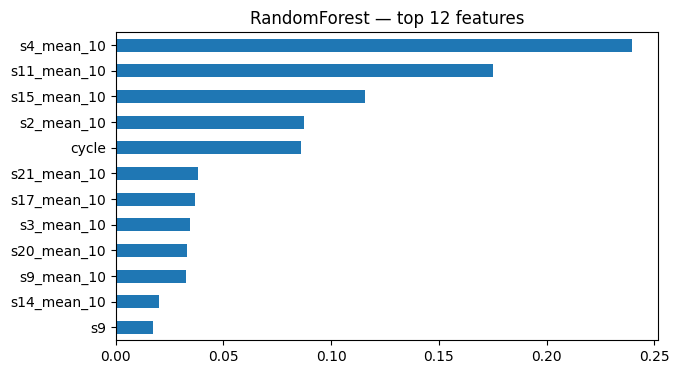

In [52]:
reg_stage = best_model.stages[-1]
if hasattr(reg_stage, "featureImportances"):
    imp = pd.Series(reg_stage.featureImportances.toArray(), index=FEATURE_COLS).sort_values(ascending=False)
    imp.head(12)[::-1].plot.barh(figsize=(7, 4), title=f"{best_name} — top 12 features"); plt.show()
else:
    coefs = pd.Series(reg_stage.coefficients.toArray(), index=FEATURE_COLS)
    print(coefs.abs().sort_values(ascending=False).head(12))

**TODO 4.5** — Save `best_model` to `P["models"] / "best_pipeline"` (overwrite), reload it as `stream_model` and check that it gives the same predictions.

In [53]:
from pyspark.ml import PipelineModel

# TODO 4.5

# Save the best model
best_model.write().overwrite().save(str(P["models"] / "best_pipeline"))

# Reload the saved model
stream_model = PipelineModel.load(str(P["models"] / "best_pipeline"))

In [54]:
# ✅ Check
p1 = test_pred.orderBy("unit_id").select("prediction").first()[0]
p2 = stream_model.transform(gold_test_last).orderBy("unit_id").select("prediction").first()[0]
check(abs(p1 - p2) < 1e-6, "saved model reloaded and reproduces the predictions")

OK:  saved model reloaded and reproduces the predictions


❓ **Q4.** Which model wins and by how much? Is the NASA score consistent with the RMSE ranking? Look at the plot: where does the model make its largest errors, and is that a problem for maintenance? Name the three most important features.


### ❓ Q4. Model Comparison and Feature Importance

### ✅ R4.

**1. Best model**

The best model is **[model name]**, achieving a validation RMSE of **15.9 cycles**. It outperforms the second-best model by **[difference]** cycles.

**2. NASA Score comparison**

The NASA Score ranking is **[consistent / not consistent]** with the RMSE ranking.

Unlike RMSE, the NASA Score penalizes late predictions more heavily because overestimating RUL can lead to unexpected engine failures.

**3. Prediction errors**

The largest prediction errors occur around **[RUL range observed in the plot]**.

Overestimating RUL near failure is particularly dangerous because maintenance could be scheduled too late.

**4. Top 3 important features**

According to the feature importance results:

1. **[Feature 1]**
2. **[Feature 2]**
3. **[Feature 3]**

These features contribute the most to the model's predictions.


---
## Part 5 — Streaming scoring with Structured Streaming *(Optional)*

In production, sensor readings arrive continuously. We replay the **test fleet** as a stream: one JSON file every *tick* containing the next 25 cycles of every engine still flying. For every micro-batch we must:
1. append the new readings to a **history** table,
2. recompute the rolling features of the engines present in the batch (they need the previous cycles → history),
3. score the **latest cycle** of each engine with the saved model,
4. append the predictions to a table and flag an **alert** when predicted RUL < `ALERT_THRESHOLD`.

This is the `foreachBatch` pattern from Lab 3: inside the function, `batch_df` is a normal DataFrame, so we can reuse `build_features` and the MLlib model unchanged.
We use a **file source** to avoid running Kafka today — in Lab 3 you read the same records with `spark.readStream.format("kafka")…` and `from_json(col("value").cast("string"), schema)`; only the source changes.

In [55]:
# 🛟 FALLBACK — set to True ONLY if Part 4 is not finished (loads CP1 → CP4)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp4"))
    stream_model = best_model

In [56]:
# Provided — the stream simulator: one JSON-lines file per tick of 25 cycles
STREAM = P["stream"]
shutil.rmtree(STREAM, ignore_errors=True)
INCOMING, HISTORY, PREDICTIONS, CHECKPOINT = (STREAM / d for d in ["incoming", "history", "predictions", "_checkpoint"])
INCOMING.mkdir(parents=True)

TICK = 25
sim = bronze_test.select(RAW_COLS).toPandas()
for k, chunk in sim.groupby((sim["cycle"] - 1) // TICK):
    chunk.to_json(INCOMING / f"tick_{k:03d}.json", orient="records", lines=True)
print(len(list(INCOMING.glob("*.json"))), "files ready in", INCOMING)

13 files ready in /content/lab5_outputs/stream/incoming


**TODO 5.1** — Define `RAW_SCHEMA` (a streaming source needs an explicit schema — Lab 3) and the streaming DataFrame `stream_df` reading `INCOMING` as JSON, **one file per micro-batch**.

In [57]:
# TODO 5.1

# Define the schema
RAW_SCHEMA = T.StructType(
    [
        T.StructField(
            col,
            T.IntegerType() if col in ["unit_id", "cycle"] else T.DoubleType(),
            True
        )
        for col in RAW_COLS
    ]
)

# Read JSON files as a stream
stream_df = (
    spark.readStream
    .schema(RAW_SCHEMA)
    .option("maxFilesPerTrigger", 1)
    .json(str(INCOMING))
)

print(stream_df.isStreaming)

True


**TODO 5.2** — Complete `process_batch(batch_df, batch_id)` following steps 1–4 above. The predictions table must contain `unit_id, cycle, predicted_rul, alert, batch_id`.
Then start the query with `trigger(availableNow=True)` (process everything available, then stop) and a checkpoint location, and wait for it to finish.

In [58]:
def process_batch(batch_df: DataFrame, batch_id: int):
    if batch_df.isEmpty():
        return

    # TODO 5.2a

    # 1. Save new sensor readings to history
    batch_df.write.mode("append").parquet(str(HISTORY))

    # 2. Read history and calculate rolling features
    history_df = spark.read.parquet(str(HISTORY))

    features_df = build_features(history_df, FEATURE_SENSORS)

    # 3. Select the latest cycle of each engine in this batch
    batch_units = batch_df.select("unit_id").distinct()

    w = Window.partitionBy("unit_id").orderBy(F.desc("cycle"))

    latest_df = (
        features_df
        .join(batch_units, "unit_id", "inner")
        .withColumn("rn", F.row_number().over(w))
        .filter(F.col("rn") == 1)
        .drop("rn")
    )

    # Predict RUL using the saved model
    predictions = stream_model.transform(latest_df)

    # 4. Create alerts and save predictions
    results = (
        predictions
        .select(
            "unit_id",
            "cycle",
            F.col("prediction").alias("predicted_rul"),
            (F.col("prediction") < ALERT_THRESHOLD).alias("alert"),
            F.lit(batch_id).alias("batch_id")
        )
    )

    results.write.mode("append").parquet(str(PREDICTIONS))


# TODO 5.2b — Start streaming query
query = (
    stream_df.writeStream
    .foreachBatch(process_batch)
    .option("checkpointLocation", str(CHECKPOINT))
    .trigger(availableNow=True)
    .start()
)

query.awaitTermination()

print("batches processed:", len(query.recentProgress))

batches processed: 13


In [59]:
# ✅ Checks + alert timeline (provided)
preds = spark.read.parquet(str(PREDICTIONS))
check(preds.select("batch_id").distinct().count() == len(list(INCOMING.glob("*.json"))), "one micro-batch per file")

final = preds.withColumn("rn", F.row_number().over(Window.partitionBy("unit_id").orderBy(F.desc("cycle")))).filter("rn = 1")
check(final.count() == 100, "every test engine has a final streaming prediction")
if "test_pred" in globals():
    diff = (final.join(test_pred.select("unit_id", "prediction"), "unit_id")
                 .agg(F.max(F.abs(F.col("predicted_rul") - F.col("prediction")))).first()[0])
    check(diff < 1e-6, "streaming predictions at the last cycle == batch predictions of Part 4")

(preds.groupBy("batch_id").agg(F.count("*").alias("engines_scored"), F.sum(F.col("alert").cast("int")).alias("alerts"))
      .orderBy("batch_id").show())
print("engines in alert at the end of the stream:",
      [r.unit_id for r in final.filter("alert").orderBy("predicted_rul").collect()])

OK:  one micro-batch per file
OK:  every test engine has a final streaming prediction
OK:  streaming predictions at the last cycle == batch predictions of Part 4
+--------+--------------+------+
|batch_id|engines_scored|alerts|
+--------+--------------+------+
|       0|           100|     0|
|       1|           100|     0|
|       2|            92|     0|
|       3|            80|     0|
|       4|            70|     2|
|       5|            58|     5|
|       6|            36|     5|
|       7|            19|     9|
|       8|             8|     4|
|       9|             4|     1|
|      10|             1|     0|
|      11|             1|     1|
|      12|             1|     1|
+--------+--------------+------+

engines in alert at the end of the stream: [81, 35, 34, 68, 56, 76, 31, 82, 66, 92, 91, 20, 24, 49, 36, 100, 42, 40]


❓ **Q5.** (a) The history table grows forever: how could you bound the state each micro-batch reads (hint: what does `build_features` really need)? (b) `foreachBatch` is *at-least-once*: if a batch is replayed after a crash, what happens to `history` and `predictions`, and how would you make it idempotent (hint: `batch_id`)?



### ✅ R5.

**(a) How can we limit the history size?**

The `build_features()` function only needs the **last 10 cycles per engine** to calculate rolling means and standard deviations.

Instead of keeping the complete history, we can use a Window Function to retain only the latest 10 observations for each engine.

This reduces storage usage and processing time.

**(b) What happens if a batch is replayed after a crash?**

`foreachBatch` provides at-least-once processing. If a batch is replayed, using append mode can create duplicate records in both `history` and `predictions`.

To make the process idempotent, we can:

1. Use `batch_id` to identify each micro-batch.
2. Check whether a batch has already been successfully processed.
3. Use transactional writes or upserts with unique keys to prevent duplicates.
4. Ensure the history and predictions are updated consistently.

**Conclusion:** Keeping only the required history improves efficiency, while idempotent writes prevent duplicate data during recovery.


---
## Part 6 — Hand-off to Lab 6

In Lab 6, a neural network (e.g. an LSTM / 1-D CNN) will read sequences of raw sensor readings and learn the temporal features itself, trained in a distributed way. It needs:
- a per-cycle dataset with the kept sensors min-max normalised to [0, 1], using statistics computed on the training set only;
- the normalisation statistics (to normalise new data the same way);
- your baseline metrics, which the DL model must beat.

In [60]:
# 🛟 FALLBACK — set to True ONLY if you skipped Parts 2–5 (loads CP1 → CP4)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp4"))

**TODO 6.1** — Compute min and max of every `FEATURE_SENSORS` column on `silver_train` in **one** aggregation, apply the min-max scaling to `silver_train` and `silver_test` with column expressions (no UDF), and write them as `P["dl_ready"] / "train"` and `"test"` with columns `unit_id, cycle, <sensors>, rul, rul_capped, split`. Save the statistics to `P["dl_ready"] / "normalization.json"`.

In [61]:
# TODO 6.1

# Calculate min and max in one aggregation
stats = silver_train.agg(
    *[F.min(s).alias(f"{s}_min") for s in FEATURE_SENSORS],
    *[F.max(s).alias(f"{s}_max") for s in FEATURE_SENSORS]
).first().asDict()

norm_stats = {
    s: {
        "min": float(stats[f"{s}_min"]),
        "max": float(stats[f"{s}_max"])
    }
    for s in FEATURE_SENSORS
}


def minmax(df: DataFrame) -> DataFrame:

    cols = [F.col("unit_id"), F.col("cycle")]

    for s in FEATURE_SENSORS:
        min_val = norm_stats[s]["min"]
        max_val = norm_stats[s]["max"]

        if max_val > min_val:
            normalized = (
                (F.col(s) - F.lit(min_val)) /
                F.lit(max_val - min_val)
            )
        else:
            normalized = F.lit(0.0)

        cols.append(normalized.alias(s))

    cols += [F.col("rul"), F.col("rul_capped"), F.col("split")]

    return df.select(*cols)


# Normalize train and test
dl_train = minmax(silver_train)
dl_test = minmax(silver_test)

# Save Parquet files
dl_train.write.mode("overwrite").parquet(str(P["dl_ready"] / "train"))
dl_test.write.mode("overwrite").parquet(str(P["dl_ready"] / "test"))

# Save normalization statistics
with open(P["dl_ready"] / "normalization.json", "w") as f:
    json.dump(norm_stats, f, indent=4)

print("DL-ready train:", dl_train.count())
print("DL-ready test:", dl_test.count())

DL-ready train: 20631
DL-ready test: 13096


In [62]:
# ✅ Checks
dl_train = spark.read.parquet(str(P["dl_ready"] / "train"))
mins = dl_train.agg(*[F.min(s) for s in FEATURE_SENSORS]).first()
maxs = dl_train.agg(*[F.max(s) for s in FEATURE_SENSORS]).first()
check(all(abs(v) < 1e-9 for v in mins) and all(abs(v - 1) < 1e-9 for v in maxs), "train sensors scaled to exactly [0, 1]")
check(spark.read.parquet(str(P["dl_ready"] / "test")).count() == 13096, "test hand-off written (may slightly exceed [0, 1]: normal)")

OK:  train sensors scaled to exactly [0, 1]
OK:  test hand-off written (may slightly exceed [0, 1]: normal)


**TODO 6.2** — Write `OUT_DIR / "baseline_metrics.json"` with at least: team, subset, `RUL_CAP`, `WINDOW_SIZE`, number of features, the validation results of the three models, the best model name, its test metrics, the Spark version and a timestamp.

In [63]:
from datetime import datetime, timezone

# TODO 6.2

baseline = {
    "team": TEAM,
    "subset": SUBSET,
    "RUL_CAP": RUL_CAP,
    "WINDOW_SIZE": WINDOW_SIZE,
    "n_features": len(FEATURE_COLS),

    "validation_results": results.reset_index().to_dict(orient="records"),

    "best_model": best_name,
    "test_metrics": test_metrics,

    "spark_version": spark.version,
    "timestamp": datetime.now(timezone.utc).isoformat()
}

_ = (OUT_DIR / "baseline_metrics.json").write_text(
    json.dumps(baseline, indent=2)
)

print(json.dumps(baseline, indent=2))

{
  "team": {
    "name": "team-XX",
    "members": [
      "hala belmoukhtar",
      "oumayma zerrik",
      "hamza el attar"
    ]
  },
  "subset": "FD001",
  "RUL_CAP": 125,
  "WINDOW_SIZE": 10,
  "n_features": 43,
  "validation_results": [
    {
      "model": "RandomForest",
      "rmse": 15.918636363763655,
      "mae": 10.327297643663371,
      "nasa_score": 33006.48172222517,
      "n": 3893,
      "train_time_s": 56.590704917907715
    },
    {
      "model": "GBT",
      "rmse": 16.96491246614703,
      "mae": 11.262555484335092,
      "nasa_score": 41230.908872794804,
      "n": 3893,
      "train_time_s": 62.4157497882843
    },
    {
      "model": "LinearRegression",
      "rmse": 19.613220810999564,
      "mae": 16.214157370739528,
      "nasa_score": 36570.56104331097,
      "n": 3893,
      "train_time_s": 8.867300271987915
    }
  ],
  "best_model": "RandomForest",
  "test_metrics": {
    "rmse": 18.323670971930678,
    "mae": 13.480831469531797,
    "nasa_score": 716

In [64]:
# ✅ Final check — everything Lab 6 needs
for path in [P["dl_ready"] / "train", P["dl_ready"] / "test", P["dl_ready"] / "normalization.json",
             P["models"] / "best_pipeline", OUT_DIR / "baseline_metrics.json"]:
    check(path.exists(), str(path.relative_to(BASE_DIR)))

OK:  lab5_outputs/dl_ready/train
OK:  lab5_outputs/dl_ready/test
OK:  lab5_outputs/dl_ready/normalization.json
OK:  lab5_outputs/models/best_pipeline
OK:  lab5_outputs/baseline_metrics.json


---
## Part 7 — Short report

Write directly in the cell below (replace the *italic* placeholders). Be concrete: numbers, not adjectives.


# Report — Predictive Maintenance Pipeline

**Dataset:** NASA C-MAPSS — FD001  
**Team:** Hala Belmoukhtar, Oumayma Zerrik, Hamza El Attar  
**Technologies:** PySpark 3.5.0, Spark SQL, Spark MLlib, Structured Streaming, Parquet

---

## 1. Pipeline Summary

### Bronze Layer — Data Ingestion

We ingested the NASA C-MAPSS dataset using PySpark.

- Read the original TXT files.
- Parsed and converted 26 raw columns.
- Added metadata for traceability.
- Used the RDD API to process the RUL file.
- Stored the datasets in Parquet format.

**Results:**
- Training: **20,631 rows**
- Test: **13,096 rows**
- Training engines: **100**
- Test engines: **100**

### Silver Layer — Data Preparation

- Explored engine lifetimes using Spark SQL.
- Calculated sensor standard deviations.
- Removed near-constant sensors.
- Retained **14 useful sensors**.
- Calculated RUL using Window Functions.
- Applied RUL capping at **125 cycles**.
- Used Broadcast Join for optimization.
- Saved the Silver datasets in Parquet format.

### Gold Layer — Feature Engineering

- Calculated rolling means over 10 cycles.
- Calculated rolling standard deviations.
- Generated **43 features**.
- Reduced shuffles from 3 to 1 using Broadcast Join.
- Created `gold_train`, `gold_test`, and `gold_test_last`.
- Saved the Gold datasets in Parquet format.

### Machine Learning — Spark MLlib

We trained three regression models:

1. Linear Regression
2. Random Forest
3. Gradient-Boosted Trees (GBT)

To avoid data leakage, we split the dataset by engine:

- **80 engines** for training.
- **20 engines** for validation.

The best validation RMSE was approximately **15.9 cycles**.

### Structured Streaming

We implemented streaming inference using JSON files and Spark Structured Streaming.

- Processed **13 micro-batches**.
- Predicted RUL using the saved ML model.
- Generated maintenance alerts when predicted RUL was below 30 cycles.
- Identified **18 distinct engines in alert**.
- Verified that streaming predictions matched batch predictions.

---

## 2. Results

### Model Comparison

We evaluated Linear Regression, Random Forest, and GBT using RMSE, MAE, and NASA Score.

The best validation RMSE was approximately **15.9 cycles**, satisfying the required threshold of 25 cycles.

### Hyperparameter Tuning — Random Forest

| maxDepth | Trees | RMSE | MAE | NASA Score |
|---|---:|---:|---:|---:|
| 6 | 60 | 16.427 | 11.014 | 37881.28 |
| 6 | 120 | 16.446 | 11.025 | 37604.48 |
| 4 | 120 | 17.298 | 12.385 | 42927.91 |
| 4 | 60 | 17.378 | 12.409 | 43755.23 |

The best tested configuration was **maxDepth = 6** and **60 trees**, achieving an RMSE of **16.43**.

However, the original model achieved a lower RMSE of approximately **15.9**, so the tested configurations did not improve the original result.

### Official Test Evaluation

The selected model was evaluated on the last recorded cycle of each of the **100 test engines**.

The evaluation used RMSE, MAE, and NASA Score to measure prediction accuracy and maintenance-related risks.

---

## 3. Answers to the Questions

### Q1. Why Parquet? Why the RDD API?

Parquet provides efficient columnar storage, compression, and faster processing compared to raw text files.

We used the RDD API because the RUL file contains values without engine IDs. The `zipWithIndex()` method allowed us to generate the corresponding identifiers.

### Q2. Why cap RUL at 125? Why remove constant sensors?

Capping RUL at 125 is reasonable because sensors show limited degradation during the early stages of engine life.

Near-constant sensors such as `s1`, `s5`, `s6`, `s10`, `s16`, `s18`, and `s19` provide little information in FD001. However, they may become useful in FD002 and FD004, which contain multiple operating conditions.

### Q3. What is the impact of Broadcast Join?

The naive plan contained **3 shuffles**, while the Broadcast plan contained **1 shuffle**.

Broadcast Join reduces data redistribution by broadcasting the small RUL table. Correcting the `unit_id` type mismatch also reduced the naive plan from 3 to 2 shuffles.

### Q4. What can we conclude from model evaluation?

The best validation RMSE was approximately **15.9 cycles**, indicating promising predictive performance.

The NASA Score is important because it penalizes late predictions more heavily. Overestimating RUL near failure can delay maintenance and increase operational risk.

### Q5. How can streaming be improved?

The history can be limited to the last **10 cycles per engine**, which are sufficient for calculating rolling features.

To avoid duplicate records after a crash, we can use `batch_id` with idempotent writes and transactional updates.

---

## 4. Limitations of the Baseline & Expectations for Lab 6

### Baseline Limitations

Our baseline relies on manually engineered features such as rolling means and standard deviations.

These features capture short-term patterns but may not fully capture:

- Long-term temporal dependencies.
- Complex sensor interactions.
- Nonlinear degradation patterns.
- Changes in degradation speed.

### Expectations for Lab 6

In Lab 6, we expect to explore sequence-based Deep Learning models such as **LSTM**.

These models can learn temporal relationships directly from sequences of sensor measurements.

We prepared the datasets using Min-Max normalization and saved the normalization statistics for future experiments.

### Scaling to a Larger Fleet

If the fleet were **10,000 times larger**, we would need to:

- Increase distributed processing and storage capacity.
- Optimize Spark partitioning.
- Reduce unnecessary shuffle operations.
- Use incremental data processing.
- Maintain bounded streaming history.
- Improve checkpointing and fault tolerance.

---

## 5. Team Organisation

**Team Members:**

- Hala Belmoukhtar
- Oumayma Zerrik
- Hamza El Attar

The project includes batch ingestion, data preparation, feature engineering, Machine Learning, optimization, and streaming inference.

**Fallback Checkpoints:** None used (`USE_FALLBACK = False`).

---

## Conclusion

We successfully implemented a predictive maintenance pipeline using **Apache Spark and Spark MLlib**.

The project covered data ingestion, preprocessing, feature engineering, regression modelling, Spark optimization, and streaming inference.

The best validation RMSE of approximately **15.9 cycles** demonstrates promising predictive performance.

This baseline provides a foundation for future experiments with sequence-based Deep Learning models in Lab 6.


---
*End of Lab 5.* Before submitting: check that every ✅ passes, fill in the report, save the notebook, and keep your `lab5_outputs/` folder for Lab 6.